# Исследование вероятности выполнения заявок логистической компанией

In [1]:
import pandas as pd 
import numpy as np 
import datetime as dt 
import itertools
import plotly as py
import plotly.graph_objs as go
import plotly.figure_factory as ff
import plotly.express as px
from dash import Dash, dcc, html, Input, Output
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import kstest, norm
from scipy.stats import norm, skew, kurtosis
import plotly.express as px
from scipy.stats import ttest_ind, mannwhitneyu

Логистическая компания занимается оказанием услуг по железнодорожной перевозке.  
Ежедневно в компанию поступают заявки на транспортировку товаров. Для каждой заявки известно направление перевозки (между какими станциями нужно осуществить транспортировку товаров), объем товаров, требующих перевозку, планируемая дата отправки, учетное направление перевозки (некоторые особенности перевозки). В течение жизненного цикла заявки (от ее регистрации в системе до её закрытия) с ней могут происходить различные изменения: изменение станций отправки и доставки, изменение величины прибыли, получаемой компанией в результате осуществления услуги по доставке, отмена заявки и т.д. 
В конце месяца из существующих заявок формируется заявочная компания, которая передается в отдел оптимизации, который составляет расписание движения составов, которое старается выполнить весь объем поступивших заявок.

**Глобальная задача:** используя инструменты машинного обучения предсказать вероятность выполнения заявки в заявочной компании. 

**Задача на сегодня**: используя инструменты визуализации данных и статистического анализа выявить признаки, которые оказывают влияние выполнение заявки.

Вам дана информацию о том, как формировалась заявочная компания с 01.01.2023 по 30.09.2023. Для каждой заявки представлены все изменения, вносимые оператором и результат выполнения заявки (выполнение, перенос, отмена).

**Описание исходных данных:**
 -   `Идентификатор погрузки` - уникальный номер погрузки в системе данных компании;
 -   `Дата редактирования` - когда вносились изменения в информацию о заявке на выполнение погрузки;   
 -   `Версия погрузки` - номер редакции;
 -   `Оператор` -  человек, осуществляющий редактирование заявки;
 -   `Дата отправления` - планируемая дата отправки погрузки;        
 -   `Дата отправления факт` - фактическая дата отправки погрузки;
 -   `Учетное направление` - тип перевозки; 
 -   `Кластер назначения`- из какого региона двигается состав;     
 -   `Кластер отправления` -  в какой регион двигается состав; 
 -   `Код назначения` - станция откуда нужно перевести товары;           
 -   `Код отправления` - станция, куда нужно перевезти товары;         
 -   `Количество вагонов` - количество вагонов в составе;      
 -   `Контрибуция` - прибыль, которую получит компания за перевозку;                         
 -   `Идентификатор переноса` - была ли перенесена погрука (-1 – заявка отменена, 0 – заявка выполнена, 1 – заявка перенесена);
 -   `Длительность жизни` -  время, которое прошло между первой и последней редакцией заявки;
 -   `Время до отправки`  - время между последней редакцией перед отправкой и плановой датой отправки;            
 -   `Количество редакций после отправки`  - сколько раз заявка редактировалась после ее отправки;        
 -   `Количество отмен` - сколько раз заявка отменялась к моменту последней редакции заявки перед отправкой;       
 -   `Количество переносов` - сколько раз заявка переносилась к моменту последней редакции заявки перед отправкой;            
 -   `Среднее время между редакциями` - сколько дней проходило в среднем между редакциями. 
            
     

**Целевой признак (результат)**: статус выполнения заявки (1 -- если заявка выполнена, 0 -- если заявка не выполнена (перенесена, отменена)). 

In [2]:
# чтобы было видно все столбцы
pd.set_option("display.max_columns", None)

In [3]:
df = pd.read_excel('../data/orders.xlsx')
df.head()

,Unnamed: 0,Идентификатор погрузки,Дата редактирования,версия погрузки,Оператор,Дата отправления,Дата отправления факт,Учетное направление,Кластер назначения,Кластер отправления,Код назначения,Код отправления,Количество вагонов,Контрибуция,Идентификатор переноса,Длительность жизни,Время до отправки,Количество редакций после отправки,Количество отмен,Количество переносов,Среднее время между редакциями,Длительность афтершока,Результат
0,0,6832,2023-01-16 10:40:00,3,operator_1,2023-01-21,NaT,(8) ВРП,ДВ,СПб,98220,3690,31,-1109524,-1,33.75,4.56,0,3,0,16.50,-4.56,0
1,1,6833,2022-12-26 17:16:00,2,operator_1,2023-01-30,NaT,(1) Экспорт морской,ДВ,СПб,98220,3690,31,-1109524,-1,12.99,34.28,3,2,0,12.00,2.36,0
2,2,6840,2022-12-27 17:01:00,4,operator_14,2023-01-15,2023-01-15 02:24:00,(8) ВРП,КРС,МСК,89210,23050,31,-394944,-1,13.10,18.29,3,4,0,3.67,8.65,1
3,3,6841,2022-12-29 15:25:00,6,operator_14,2023-01-23,2023-01-23 10:54:00,(8) ВРП,КРС,МСК,89210,18290,31,-259944,0,15.03,24.36,0,5,0,2.20,-23.36,1
4,4,6843,2022-12-26 17:16:00,6,operator_14,2023-01-05,2023-01-05 14:58:00,(8) ВРП,ДВ,МСК,98830,23860,16,-843599,0,12.11,9.28,0,3,2,2.20,-9.28,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3190 entries, 0 to 3189
Data columns (total 23 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Unnamed: 0                          3190 non-null   int64         
 1   Идентификатор погрузки              3190 non-null   int64         
 2   Дата редактирования                 3190 non-null   datetime64[us]
 3   версия погрузки                     3190 non-null   int64         
 4   Оператор                            3190 non-null   str           
 5   Дата отправления                    3190 non-null   datetime64[us]
 6   Дата отправления факт               1826 non-null   datetime64[us]
 7   Учетное направление                 3190 non-null   str           
 8   Кластер назначения                  3190 non-null   str           
 9   Кластер отправления                 3190 non-null   str           
 10  Код назначения                     

# Исследовательский анализ

Начнем исследовательский анализ с рассмотрения количественных признаков. 
1. Определите, какие признаки относятся к количественным. Выведите их описательные статистики.
2. Выполните проверку на нормальность количественных признаков следующими методами:
   - постройте гистограмму;
   - постройте кумулятивное распределение;
   - постройте график квантиль-квантиль;
   - вычислите коэффициенты асимметрии и эксцесса;
   - проведите тестирование данных на нормальность.
3. Для каждого способа проверки на нормальность сделайте выводы.
4. При выполнении графических видов проверки данных на нормальность, постройте динамичесий график с использованим библиотеку dash. При работе с диаграммой пользователь выбирает наименование количественного признака, для которого необходимо провести проверку на нормальность, а в результате получает график с результатом. 

## Описательные статистики

In [5]:
numerical = [
    'версия погрузки',
    'Количество вагонов',
    'Контрибуция', 
    'Длительность жизни',
    'Время до отправки',
    'Количество редакций после отправки',
    'Количество отмен', 
    'Количество переносов',
    'Среднее время между редакциями', 
    'Длительность афтершока']

df[numerical].describe()

,версия погрузки,Количество вагонов,Контрибуция,Длительность жизни,Время до отправки,Количество редакций после отправки,Количество отмен,Количество переносов,Среднее время между редакциями,Длительность афтершока
count,3190.000000,3190.000000,3.190000e+03,3190.000000,3190.000000,3190.000000,3190.000000,3190.000000,3190.000000,3190.000000
mean,3.759248,31.578056,1.062770e+06,9.139006,10.191777,0.863950,2.765517,0.657994,3.099542,-3.239984
std,2.608998,10.529060,2.476254e+06,10.854553,10.282935,1.501432,1.895896,1.172737,5.142586,14.826444
min,1.000000,0.000000,-6.522400e+07,0.000000,0.070000,0.000000,0.000000,0.000000,-1.000000,-44.480000
25%,2.000000,31.000000,0.000000e+00,0.000000,1.700000,0.000000,1.000000,0.000000,0.000000,-11.537500
50%,3.000000,31.000000,0.000000e+00,5.095000,5.795000,0.000000,2.000000,0.000000,1.200000,-0.750000
75%,5.000000,31.000000,1.974068e+06,15.282500,16.540000,1.000000,4.000000,1.000000,4.000000,3.277500
max,27.000000,71.000000,1.519000e+07,61.820000,53.040000,27.000000,17.000000,9.000000,42.000000,104.510000


## Проверка на нормальность

### Гистограмма

In [6]:
# приложение
app = Dash(__name__)

app.layout = html.Div([
    html.H4('Интерактивная гистограмма'),
    html.P('Признак:'),
    dcc.Dropdown(
        options=[{'label': col, 'value': col} for col in numerical],
        value=numerical[0],
        id='dropdown_value'
    ),
    dcc.Graph(id="graph"),
])

@app.callback(
    Output("graph", "figure"), 
    Input("dropdown_value", "value")
)
def display_hist(dropdown_value):
    fig = ff.create_distplot(
        [df[dropdown_value].dropna().tolist()],
        [dropdown_value],
        show_rug=True
    )
    return fig

# запуск в Jupyter
app.run(mode="inline", debug=True)

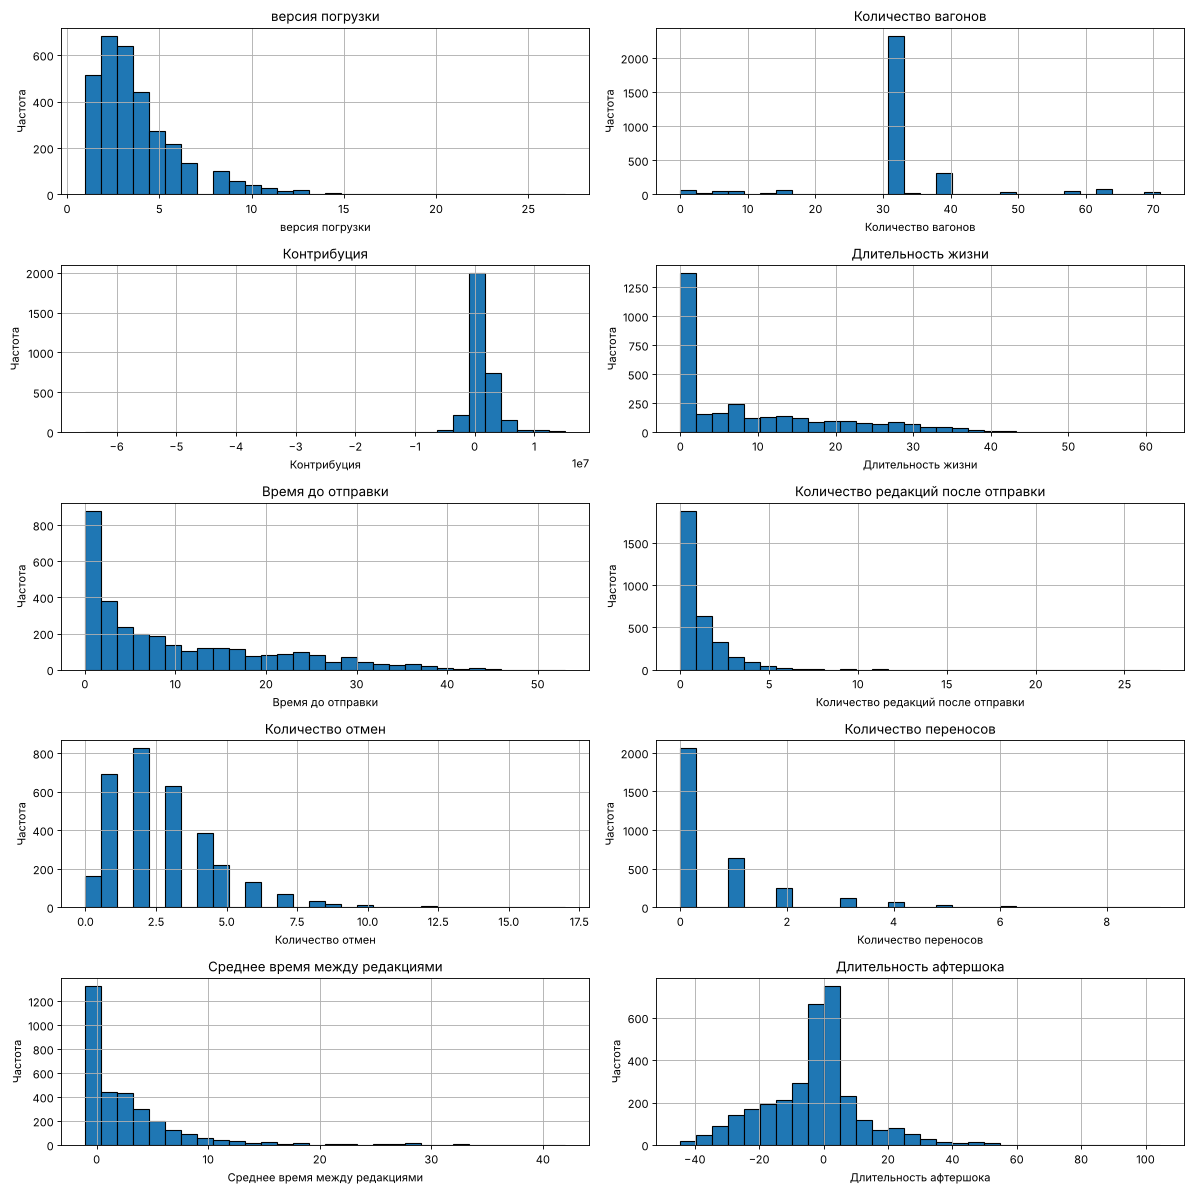

In [7]:
plt.figure(figsize=(15, 15))

for i, col in enumerate(numerical, 1):
    plt.subplot(5, 2, i)
    df[col].hist(bins=30, edgecolor="black")
    plt.title(col)
    plt.xlabel(col)
    plt.ylabel("Частота")

plt.tight_layout()
plt.show()

### Кумулятивное распределение

In [8]:
cdf = Dash(__name__)

cdf.layout = html.Div([
    html.H2("Кумулятивное распределение признаков", style={"textAlign": "center"}),

    html.Div([
        html.Label("Выбери признак:", style={"fontSize": "18px"}),
        dcc.Dropdown(
            id="dropdown_value",
            options=[{"label": col, "value": col} for col in numerical],
            value=numerical[0],
            clearable=False,
            style={"width": "60%"}
        )
    ], style={"textAlign": "center", "marginBottom": "20px"}),

    dcc.Graph(id="graph", style={"height": "80vh"})
])


@cdf.callback(
    Output("graph", "figure"),
    Input("dropdown_value", "value")
)
def update_cdf(column):
    fig = px.histogram(
        df, 
        x=column, 
        nbins=50,
        cumulative=True,   
        histnorm="probability",
        title=f"Кумулятивное распределение: {column}"
    )
    fig.update_layout(
        bargap=0.05,
        template="plotly_white"
    )
    return fig


if __name__ == "__main__":
    cdf.run(debug=True)

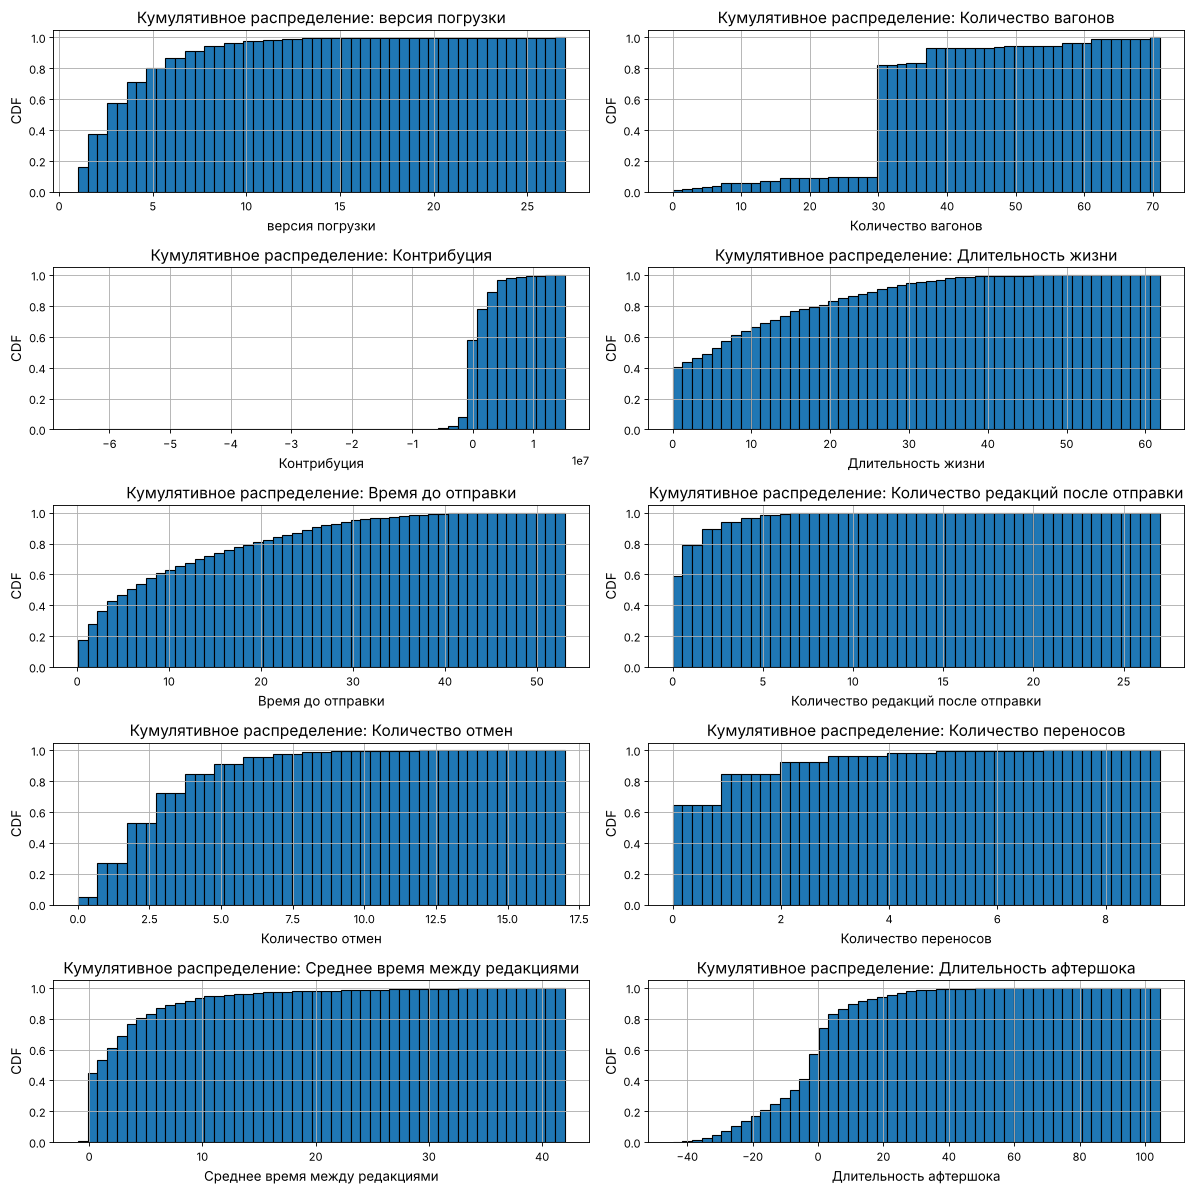

In [9]:
plt.figure(figsize=(15, 15))

for i, col in enumerate(numerical, 1):
    plt.subplot(5, 2, i)
    df[col].hist(bins=50, cumulative=True, density=True, edgecolor="black")
    plt.title(f"Кумулятивное распределение: {col}", fontsize=14)
    plt.xlabel(col, fontsize=12)
    plt.ylabel("CDF", fontsize=12)

plt.tight_layout()
plt.show()

### График квантиль -  квантиль

In [10]:
qq = Dash(__name__)

qq.layout = html.Div([
    html.H2("Q–Q график признаков", style={"textAlign": "center"}),

    html.Div([
        html.Label("Выбери признак:", style={"fontSize": "18px"}),
        dcc.Dropdown(
            id="dropdown_value",
            options=[{"label": col, "value": col} for col in numerical],
            value=numerical[0],
            clearable=False,
            style={"width": "60%"}
        )
    ], style={"textAlign": "center", "marginBottom": "20px"}),

    dcc.Graph(id="qq_graph", style={"height": "80vh"})
])


@qq.callback(
    Output("qq_graph", "figure"),
    Input("dropdown_value", "value")
)
def update_qq(column):
    data = df[column].dropna().values

    (osm, osr), _ = stats.probplot(data, dist="norm")

    fig = go.Figure()

    # точки
    fig.add_trace(go.Scatter(
        x=osm, y=osr, mode="markers",
        name="Данные", marker=dict(color="blue", size=6, opacity=0.7)
    ))
    
    fig.add_trace(go.Scatter(
        x=[min(osm), max(osm)], 
        y=[min(osm), max(osm)], 
        mode="lines", 
        name="Нормальное распределение", 
        line=dict(color="red", dash="dash")
    ))

    fig.update_layout(
        title=f"Q–Q график: {column}",
        xaxis_title="Теоретические квантили",
        yaxis_title="Наблюдаемые квантили",
        template="plotly_white"
    )
    return fig


if __name__ == "__main__":
    qq.run(debug=True)

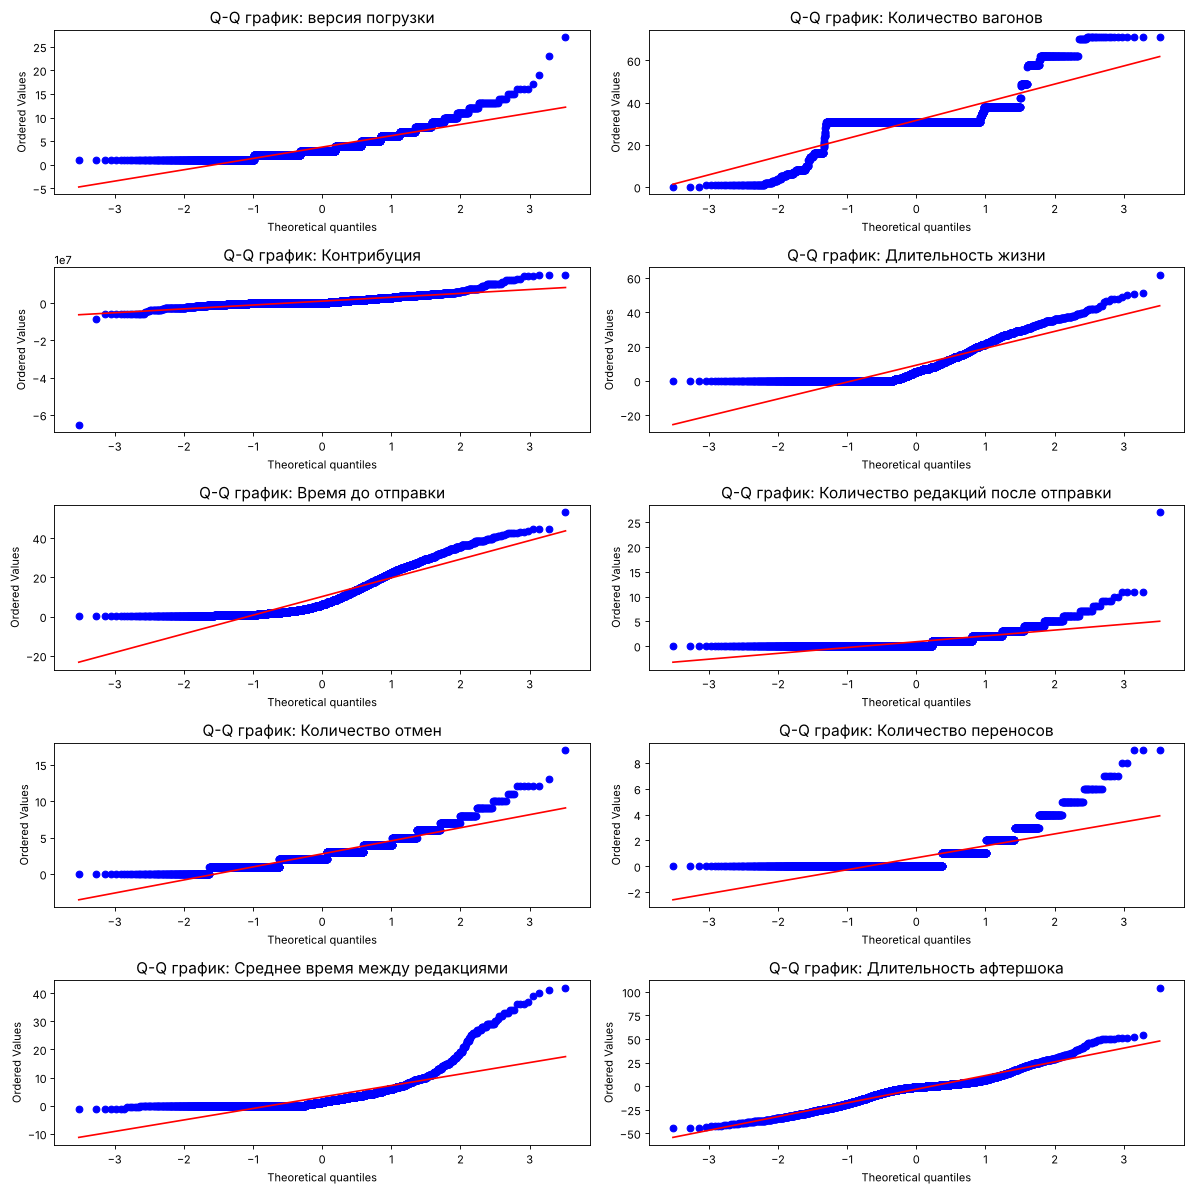

In [11]:
plt.figure(figsize=(15, 15))

for i, col in enumerate(numerical, 1):
    plt.subplot(5, 2, i) 
    stats.probplot(df[col].dropna(), dist="norm", plot=plt)
    plt.title(f"Q-Q график: {col}", fontsize=14)

plt.tight_layout()
plt.show()

### Проверка с использованием коэффициентов асимметрии и эксцесса

In [12]:
app = Dash(__name__)

app.layout = html.Div([
    html.H2("Асимметрия и эксцесс признаков", style={"textAlign": "center"}),

    html.Div([
        html.Label("Выбери признак:", style={"fontSize": "18px"}),
        dcc.Dropdown(
            id="dropdown_value",
            options=[{"label": col, "value": col} for col in numerical],
            value=numerical[0],
            clearable=False,
            style={"width": "60%"}
        )
    ], style={"textAlign": "center", "marginBottom": "20px"}),

    html.Div(id="stats_output", style={"fontSize": "18px", "textAlign": "center", "marginBottom": "20px"}),

    dcc.Graph(id="hist_graph", style={"height": "70vh"})
])


@app.callback(
    [Output("stats_output", "children"),
     Output("hist_graph", "figure")],
    Input("dropdown_value", "value")
)
def update_stats(column):
    data = df[column].dropna().values

    skewness = skew(data)
    kurt = kurtosis(data)

    stats_text = f"Асимметрия: {skewness:.3f} | Эксцесс: {kurt:.3f}"

    fig = go.Figure()
    fig.add_trace(go.Histogram(x=data, nbinsx=30, marker_color="skyblue", opacity=0.7))
    fig.update_layout(
        title=f"Распределение признака: {column}",
        xaxis_title=column,
        yaxis_title="Частота",
        template="plotly_white"
    )

    return stats_text, fig


if __name__ == "__main__":
    app.run(debug=True)

In [13]:
stats_df = pd.DataFrame({
    "Признак": numerical,
    "Асимметрия (skew)": [skew(df[col].dropna()) for col in numerical],
    "Эксцесс (kurtosis)": [kurtosis(df[col].dropna()) for col in numerical]
})

stats_df

,Признак,Асимметрия (skew),Эксцесс (kurtosis)
0,версия погрузки,1.748288,5.282866
1,Количество вагонов,0.387212,4.294761
2,Контрибуция,-4.919654,163.588515
3,Длительность жизни,1.133928,0.456261
4,Время до отправки,1.077447,0.238743
5,Количество редакций после отправки,3.811720,35.247293
6,Количество отмен,1.342867,3.167019
7,Количество переносов,2.500764,7.894588
8,Среднее время между редакциями,3.249227,13.754638
9,Длительность афтершока,0.243820,1.777520


### Проверка с использованием тестов

- тест Шапиро-Уилка – для небольших размеров выборки (<50 выборок)
- тест Колмогорова-Смирнова – для n ≥ 50

Для обоих вышеуказанных тестов нулевая гипотеза $H_0$ утверждает, что данные взяты из нормально распределенной совокупности.

In [14]:
results = []

for col in numerical:
    data = df[col].dropna().values
    
    standardized = (data - np.mean(data)) / np.std(data, ddof=1)
    
    stat, p_value = kstest(standardized, 'norm')
    
    results.append({
        "Признак": col,
        "KS-статистика": stat,
        "p-value": p_value,
        "Гипотеза H0 (норма)": "отвергается" if p_value < 0.05 else "не отвергается"
    })

ks_results = pd.DataFrame(results)
ks_results

,Признак,KS-статистика,p-value,Гипотеза H0 (норма)
0,версия погрузки,0.190968,2.342867e-102,отвергается
1,Количество вагонов,0.381243,0.000000e+00,отвергается
2,Контрибуция,0.179438,2.460215e-90,отвергается
3,Длительность жизни,0.199908,3.279841e-112,отвергается
4,Время до отправки,0.165739,4.723209e-77,отвергается
5,Количество редакций после отправки,0.306837,4.066466e-267,отвергается
6,Количество отмен,0.183457,1.942263e-94,отвергается
7,Количество переносов,0.358081,0.000000e+00,отвергается
8,Среднее время между редакциями,0.267078,2.164962e-201,отвергается
9,Длительность афтершока,0.104998,4.473916e-31,отвергается


### Итоговые выводы

К **количественным признакам отнесены**: версия погрузки, Количество вагонов, Контрибуция, Длительность жизни, Время до отправки, Количество редакций после отправки, Количество отмен, Количество переносов, Среднее время между редакциями, Длительность афтершока.<br>

Анализ распределений показал, что все признаки статистически отклоняются от нормального закона (по тесту Колмогорова–Смирнова во всех случаях **p ≈ 0**). Гистограммы и кумулятивные кривые подтверждают это: у большинства признаков ярко выражены правые хвосты и концентрация значений вблизи малых чисел. Q–Q графики наглядно демонстрируют систематические отклонения точек от диагонали, особенно в хвостах.

*   **«Версия погрузки»**: положительная асимметрия (**1.75**) и тяжёлые хвосты (эксцесс **5.28**)
*   **«Количество вагонов»**: скошенность и повышенный эксцесс (**0.39**; **4.29**)
*   **«Контрибуция»**: экстремальная отрицательная асимметрия (**-4.92**) и очень высокий эксцесс (**163.6**), что указывает на наличие сильных выбросов
*   **«Длительность жизни»** и **«Время до отправки»**: ближе к экспоненциальному виду (асимметрия около 1, умеренный эксцесс), при этом на Q–Q графиках хвосты значительно отклоняются
*   **«Количество редакций после отправки»**, **«Количество отмен»**, **«Количество переносов»** и **«Среднее время между редакциями»**: значительная правосторонняя асимметрия (от **1.3 до 3.8**) и высокие значения эксцесса (от **3 до 35**), что отражает скошенность и вытянутые хвосты
*   **«Длительность афтершока»**: наиболее близок к нормальному — асимметрия низкая (**0.24**), эксцесс **1.78**, а на Q–Q графике точки расположены ближе к диагонали (хотя хвосты всё равно расходятся); формально же и для него гипотеза нормальности отвергается

Таким образом, **ни один из признаков не имеет нормального распределения**: почти все они демонстрируют скошенность, тяжёлые хвосты или выбросы, а визуализации полностью согласуются с результатами формальных статистических тестов.